In [1]:
import os
import h5py
import numpy as np
import json

import matplotlib.pyplot as plt
import flash_amr_tools

from transform_data import get_transformed_data
from utils import get_polar_grid, get_shock_mask

In [2]:
theta_ranges = [(0,30), (30,60), (60,90), (90,120), (120,150),(150,180)]

In [3]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

In [5]:
for sim_name in bowshock_config.keys():
    for shock_type in ["term", "outer"]:
        sim_dir = bowshock_config[sim_name]["sim_dir"]

        # get list of all files
        sim_files = []
        for file in os.listdir(f"{flash_output_dir}/{sim_dir}"):
            if file.find("plt") < 0 or file.find("forced") > 0:
                continue
            sim_files.append(file)

        # sort 
        sim_files = sorted(sim_files)

        times = np.zeros(len(sim_files))

        einj_cube_data = np.zeros((1024, 512, 512), dtype=np.float32)
        field_polar_vals = np.zeros((len(sim_files), len(theta_ranges)))

        for isim, sim_file in enumerate(sim_files):
            blist, brefs, bns = flash_amr_tools.get_true_blocks(f"{flash_output_dir}/{sim_dir}/{sim_file}")

            # open file
            pf = h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}")

            ref_lvl = pf["refine level"][()][blist]
            bbox = pf["bounding box"][()][blist]
            bsize = pf["block size"][()][blist]
            time = pf["real scalars"][()][0][1]  # time in seconds
            times[isim] = time

            field_data = get_transformed_data(pf, "encr", blist)

            # convert to uniform grid
            field_cube = flash_amr_tools.get_cube(field_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)
            shck_mask_data = get_shock_mask(pf, blist, shock=shock_type)
            shck_mask_cube = flash_amr_tools.get_cube(shck_mask_data, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

            %reset_selective -f blist, brefs, bns, ref_lvl, bbox, bsize, field_data, shck_mask_data

            if isim > 0:
                einj_cube_data = field_cube - einj_cube_data
                
                %reset_selective -f field_cube

                # get polar grid -> in future we should think of a way to get these results without uniform grid :) which will give speed up in calculation
                _, TH, _, _ = get_polar_grid(einj_cube_data.shape, bbox, derivs=False)

                field_polar_vals[isim,:] = np.array([
                    np.mean(einj_cube_data[(shck_mask_cube == True) & (TH >= np.deg2rad(theta_ranges[i][0])) & (TH < np.deg2rad(theta_ranges[i][1])) & (~np.isnan(einj_cube_data))]) for i in range(len(theta_ranges))
                ])

                %reset_selective -f shck_mask_cube, TH

            pf.close()

        # save the data
        with h5py.File(f"{data_dir}/polar_time_series_einj_{shock_type}.h5", "a") as file:
            if sim_name in list(file.keys()):
                sim_gr = file[sim_name]
                del file[sim_name]["times"]
                del file[sim_name]["theta_ranges"]
                sim_gr.create_dataset("times", data=times)
                sim_gr.create_dataset("theta_ranges", data=theta_ranges)
            else:
                sim_gr = file.create_group(sim_name)
                sim_gr.create_dataset("times", data=times)
                sim_gr.create_dataset("theta_ranges", data=theta_ranges)
                
                sim_gr.create_dataset("einj", data=field_polar_vals)

        for i in range(len(theta_ranges)):
            plt.plot(times, field_polar_vals[:,i], label=f"{theta_ranges[i][0]}-{theta_ranges[i][1]} deg", color=f"C{i}")
        plt.legend()

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
1024 1024
Biggest block has refinement level: 4
Highest refinement level in simulation: 4
Highest refinement level in selected box: 4
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 1024
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419

(1e-13, 1e-10)

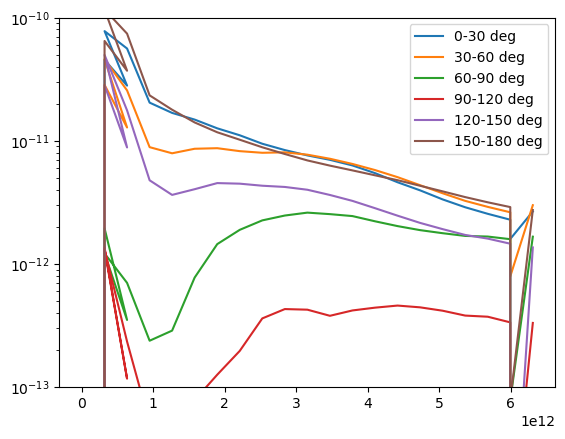

In [11]:
for i in range(len(theta_ranges)):
    plt.plot(times, field_polar_vals[:,i], label=f"{theta_ranges[i][0]}-{theta_ranges[i][1]} deg", color=f"C{i}")
plt.legend()
plt.yscale("log")
plt.ylim(1e-13, 1e-10)